## Imports

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import kagglehub

from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier


/home/orlandojunior/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Download latest version
path = kagglehub.competition_download('playground-series-s6e10')

print("Path to competition files:", path)

Path to competition files: /home/orlandojunior/.cache/kagglehub/competitions/playground-series-s6e10


## Leitura dos dados

In [3]:
df_train  = pd.read_csv(f'{path}/train.csv')
df_test  = pd.read_csv(f'{path}/test.csv')

In [4]:
def make_mi_scores(X, y, discrete_features):
    mi_scores = mutual_info_regression(X, y, discrete_features=discrete_features)
    mi_scores = pd.Series(mi_scores, name="MI Scores", index=X.columns)
    mi_scores = mi_scores.sort_values(ascending=False)
    return mi_scores

def plot_mi_scores(scores):
    scores = scores.sort_values(ascending=True)
    width = np.arange(len(scores))
    ticks = list(scores.index)
    plt.barh(width, scores)
    plt.yticks(width, ticks)
    plt.title("Mutual Information Scores")

In [5]:
pipeline = Pipeline(
    steps=[
        ('imputer',SimpleImputer(missing_values=np.nan, strategy='mean'))
    ]
)
numeric_features = df_train.select_dtypes(include=['number']).columns
df_train[numeric_features] = pipeline.fit_transform(df_train[numeric_features])

In [6]:
df_train.isna().sum()

id                                   0
Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Gender                               0
Customer Type                        0
Type of Travel                       0
Class                                0
satisfaction                         0
dtype: int64

In [7]:
X = df_train.copy()
y = X.pop("satisfaction")

for colname in X.select_dtypes("object"):
    X[colname], _ = X[colname].factorize()

discrete_features = X.dtypes == int

/tmp/ipykernel_23975/3105762954.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for colname in X.select_dtypes("object"):


In [8]:
mi_scores = make_mi_scores(X, y, discrete_features)
mi_scores[::3] 

Online boarding                      0.239675
Inflight wifi service                0.122811
Seat comfort                         0.102785
Leg room service                     0.067107
Ease of Online booking               0.051841
Checkin service                      0.038898
Departure/Arrival time convenient    0.001627
id                                   0.000035
Name: MI Scores, dtype: float64

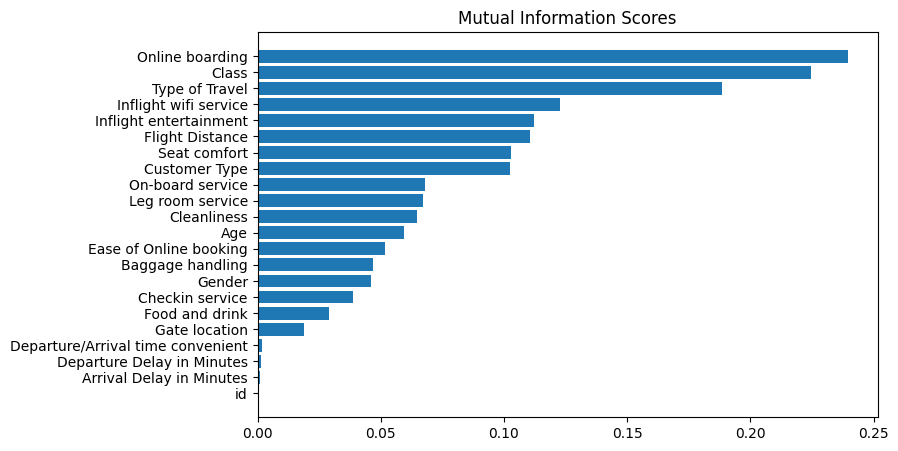

In [9]:
plt.figure(dpi=100, figsize=(8, 5))
plot_mi_scores(mi_scores)

In [10]:
df_train['Inflight wifi service'].head()

0    4.0
1    5.0
2    3.0
3    3.0
4    3.0
Name: Inflight wifi service, dtype: float64

In [11]:
def feature_engineering(df_train: pd.DataFrame, df_test: pd.DataFrame):
    ids = df_test['id']

    df_test = df_test.drop(columns=['id'])
    df_train = df_train.drop(columns=['id'])

    df = pd.concat([df_train,df_test],axis=0)
    df['satisfaction'] = df['satisfaction'].apply(lambda x: 1 if x == True else 0)
    df['inflight_service'] = (df['Inflight wifi service'] + df['Inflight entertainment'])/2
    
    return df, ids
    
    
    

In [12]:
df, ids = feature_engineering(df_train, df_test)

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 999479 entries, 0 to 299843
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Age                                999479 non-null  float64
 1   Flight Distance                    999479 non-null  float64
 2   Inflight wifi service              999479 non-null  float64
 3   Departure/Arrival time convenient  999479 non-null  float64
 4   Ease of Online booking             999479 non-null  float64
 5   Gate location                      999479 non-null  float64
 6   Food and drink                     999479 non-null  float64
 7   Online boarding                    999479 non-null  float64
 8   Seat comfort                       999479 non-null  float64
 9   Inflight entertainment             999479 non-null  float64
 10  On-board service                   999479 non-null  float64
 11  Leg room service                   999479 non-null  flo

In [14]:
features_numericas = df.select_dtypes(include=['number']).columns
features_categoricas = df.select_dtypes(include=['str']).columns

In [15]:
df[features_numericas].head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,inflight_service
0,36.0,694.0,4.0,4.0,4.0,3.0,1.0,4.0,1.0,1.0,3.0,4.0,4.0,3.0,1.0,0.0,0.0,0,2.5
1,56.0,651.0,5.0,5.0,5.0,5.0,5.0,4.0,4.0,5.0,5.0,5.0,5.0,4.0,3.0,0.0,0.0,1,5.0
2,31.0,1371.0,3.0,4.0,2.0,5.0,3.0,3.0,3.0,3.0,4.0,3.0,4.0,5.0,3.0,0.0,0.0,0,3.0
3,10.0,1616.0,3.0,5.0,3.0,3.0,3.0,3.0,3.0,3.0,4.0,5.0,3.0,4.0,3.0,0.0,0.0,0,3.0
4,23.0,481.0,3.0,4.0,3.0,4.0,5.0,3.0,5.0,5.0,5.0,4.0,5.0,3.0,5.0,5.0,0.0,0,4.0


In [16]:
for col in features_categoricas:
    print(f'{col} - {df[col].unique()}')

Gender - <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Customer Type - <StringArray>
['Loyal Customer', 'disloyal Customer']
Length: 2, dtype: str
Type of Travel - <StringArray>
['Personal Travel', 'Business travel']
Length: 2, dtype: str
Class - <StringArray>
['Eco', 'Business', 'Eco Plus']
Length: 3, dtype: str


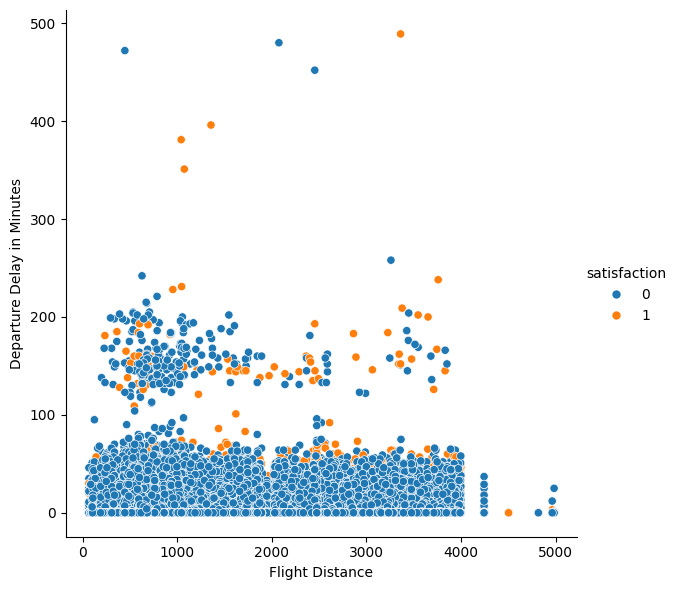

In [17]:
sns.relplot(
    x=df['Flight Distance'], y=df['Departure Delay in Minutes'], hue=df['satisfaction'],data=df, height=6,
);

In [18]:
features = ['Flight Distance','Departure Delay in Minutes']

kmeans = KMeans(n_clusters=3)
df["Cluster"] = kmeans.fit_predict(df[features])
df["Cluster"] = df["Cluster"].astype("category")

In [19]:
df.select_dtypes(include=['number']).columns

Index(['Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction', 'inflight_service'],
      dtype='str')

In [20]:
features_to_ordinal = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Cleanliness', 'inflight_service'
]

features_to_scaler = ['Age', 'Flight Distance',
                      'Departure Delay in Minutes', 'Arrival Delay in Minutes']

features_to_one_hot = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

preprocessor = ColumnTransformer(
    transformers=[
        ('ord', OrdinalEncoder(), features_to_ordinal),
        ('scaler', StandardScaler(), features_to_scaler),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         features_to_one_hot),
    ],
    remainder='passthrough'
)

new_transform_data = preprocessor.fit_transform(df)
names = preprocessor.get_feature_names_out()

new_df = pd.DataFrame(data=new_transform_data, columns=names)
new_df.head()

,ord__Inflight wifi service,ord__Departure/Arrival time convenient,ord__Ease of Online booking,ord__Gate location,ord__Food and drink,ord__Online boarding,ord__Seat comfort,ord__Inflight entertainment,ord__On-board service,ord__Leg room service,...,cat__Gender_Male,cat__Customer Type_Loyal Customer,cat__Customer Type_disloyal Customer,cat__Type of Travel_Business travel,cat__Type of Travel_Personal Travel,cat__Class_Business,cat__Class_Eco,cat__Class_Eco Plus,remainder__satisfaction,remainder__Cluster
0,4.0,4.0,4.0,3.0,1.0,4.0,1.0,1.0,3.0,4.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
1,5.0,5.0,5.0,5.0,5.0,4.0,4.0,5.0,5.0,5.0,...,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,3.0,4.0,2.0,5.0,3.0,3.0,3.0,3.0,4.0,3.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,2.0
3,3.0,5.0,3.0,3.0,3.0,3.0,3.0,3.0,4.0,5.0,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,2.0
4,3.0,4.0,3.0,4.0,5.0,3.0,5.0,5.0,5.0,4.0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [21]:
df_training = new_df[:len(df_train)]
df_testing = new_df[len(df_train):]

In [22]:
df_testing = df_testing.drop(columns=['remainder__satisfaction'])

In [23]:
X = df_training.drop(columns=['remainder__satisfaction'])
y = df_training['remainder__satisfaction']

X_train, X_temp, y_train, y_temp = train_test_split(X,y,test_size=0.3,shuffle=True, 
                                                    random_state=0, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,test_size=0.5,shuffle=True, 
                                                    random_state=0, stratify=y_temp)

print(X_train.shape, X_val.shape, X_test.shape)

(489744, 28) (104945, 28) (104946, 28)


In [24]:

xgb_clf = XGBClassifier(n_estimators = 1000,
                        learning_rate = 0.03,
                        eval_metric = "auc",
                        early_stopping_rounds = 5,
                        n_jobs = -1)

xgb_clf.fit(X_train, y_train,                    
            eval_set = [(X_val,y_val)])

[0]	validation_0-auc:0.94388
[1]	validation_0-auc:0.94472
[2]	validation_0-auc:0.94488
[3]	validation_0-auc:0.94490
[4]	validation_0-auc:0.94491
[5]	validation_0-auc:0.94499
[6]	validation_0-auc:0.94520
[7]	validation_0-auc:0.94525
[8]	validation_0-auc:0.94571
[9]	validation_0-auc:0.94580
[10]	validation_0-auc:0.94589
[11]	validation_0-auc:0.94589
[12]	validation_0-auc:0.94602
[13]	validation_0-auc:0.94602
[14]	validation_0-auc:0.94594
[15]	validation_0-auc:0.94667
[16]	validation_0-auc:0.94741
[17]	validation_0-auc:0.94756
[18]	validation_0-auc:0.94799
[19]	validation_0-auc:0.94804
[20]	validation_0-auc:0.94814
[21]	validation_0-auc:0.94815
[22]	validation_0-auc:0.94820
[23]	validation_0-auc:0.94832
[24]	validation_0-auc:0.94834
[25]	validation_0-auc:0.94841
[26]	validation_0-auc:0.94854
[27]	validation_0-auc:0.94864
[28]	validation_0-auc:0.94870
[29]	validation_0-auc:0.94874
[30]	validation_0-auc:0.94882
[31]	validation_0-auc:0.94888
[32]	validation_0-auc:0.94897
[33]	validation_0-au

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",5
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from

In [25]:
y_pred = xgb_clf.predict(X_test)

print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93     59616
           1       0.90      0.93      0.91     45330

    accuracy                           0.92    104946
   macro avg       0.92      0.92      0.92    104946
weighted avg       0.92      0.92      0.92    104946



<Axes: >

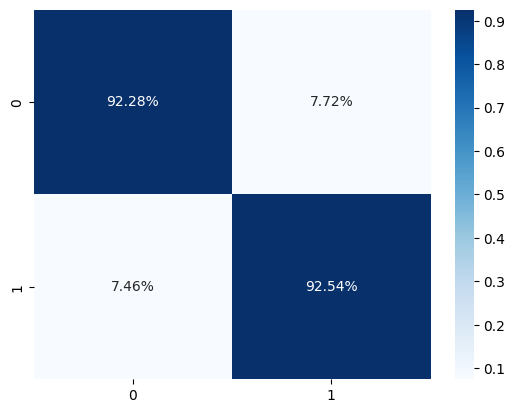

In [26]:
cm = confusion_matrix(y_pred, y_test, normalize='true')

sns.heatmap(
    cm,
    fmt='.2%',
    cmap='Blues',
    annot=True
)

In [27]:
pred_final = xgb_clf.predict_proba(df_testing)[:, 1]

df_final = pd.DataFrame({
    "id":ids,
    "satisfaction":pred_final
})

df_final.to_csv('submission.csv', index=False)